# Part II - Suspect counts vs rates by nationality (Germany, PKS 2025)
## by Oliver Maerz

## Investigation Overview

We look at how suspect counts and rates per 100k differ by nationality in German police crime statistics (PKS 2025). Absolute counts alone can be misleading when population sizes differ a lot, so the focus is rates and how they change across a few selected offence groups.

Questions:
- Which nationalities dominate absolute suspect counts (including Germany)?
- How do those same groups look once expressed as suspects per 100k?
- Does that picture change across selected aggregate offence groups (e.g. theft, violent crime, offences against life)?

### Key findings
- Not surprisingly, Germans dominate absolute suspect counts because of population size, but their rate per 100k is much lower.
- Ranking by rate differs a lot from ranking by absolute counts.
- Gaps between nationalities change by offence group. Countries that are high for one crime group are not automatically high for the others.
- Some nationalities stand out on related offence groups. Syria leads on brutality and violent crime. Romania leads on both theft-related groups.
- Among the top 5 absolute leaders, the Syrian sexual assault & rape rate is about 8.4 times Germany's; offences against life about 7.9 times Germany's.

## Dataset Overview

The plots use a cleaned dataset built [during exploration](Part_I_notebook.ipynb) from:
- BKA suspects by offence and nationality (Federal Criminal Police Office, PKS 2025)
- Destatis population by citizenship (31 Dec 2024), with the youngest age band approximated so totals better match BKA age 8+

The file loaded here (`data/polished_dataset.csv`) keeps the top 15 nationalities by absolute overall suspects, with rates per 100k for overall crime and the selected offence groups.

In [13]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# suppress warnings from final output
import warnings
warnings.simplefilter("ignore")

In [14]:
OVERALL_KEY = '890000'
CLUSTER_TOP_N = 5
RARE_KEYS = {'000000', '111000', '726200'}
PLOT_COLOR = 'orange'
SECONDARY_COLOR = 'steelblue'

df = pd.read_csv('data/polished_dataset.csv')

detail = df[df['key'] != OVERALL_KEY].copy()
overall = df[df['key'] == OVERALL_KEY].copy()
top_abs = overall.nlargest(15, 'suspects')
top_cluster = top_abs.head(CLUSTER_TOP_N)['nationality']
cluster_base = detail[detail['nationality'].isin(top_cluster)].copy()
cluster_base['offence_label'] = cluster_base['offence'].str.slice(0, 30)
cluster_high = cluster_base[~cluster_base['key'].isin(RARE_KEYS)]
cluster_rare = cluster_base[cluster_base['key'].isin(RARE_KEYS)]

## Population vs rate

Among the top absolute nationalities, Germany has by far the largest population but a much lower overall rate per 100k. Ranking by rate differs a lot from ranking by absolute counts, so absolute leaders are not the same as rate leaders.

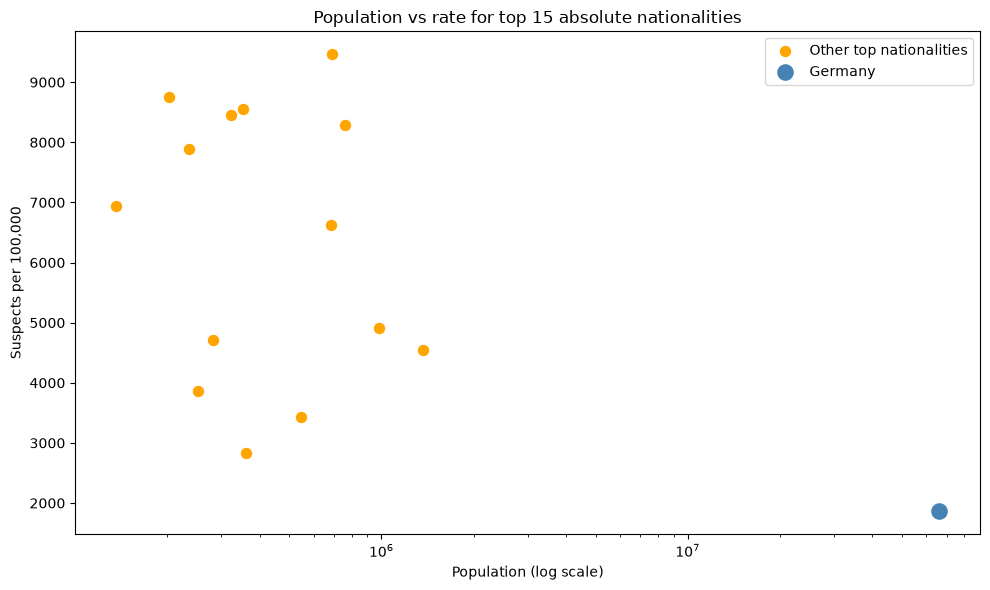

In [15]:
plt.figure(figsize=(10, 6))

de = top_abs[top_abs['nationality'] == 'Germany']
others = top_abs[top_abs['nationality'] != 'Germany']

sns.scatterplot(
    data=others,
    x='population',
    y='suspects_per_100k',
    color=PLOT_COLOR,
    s=80,
    label='Other top nationalities',
)

if len(de):
    plt.scatter(
        de['population'], de['suspects_per_100k'],
        s=120, c=SECONDARY_COLOR, zorder=5,
        label='Germany',
    )
    
plt.xscale('log')
plt.xlabel('Population (log scale)')
plt.ylabel('Suspects per 100,000')
plt.title(f'Population vs rate for top {len(top_abs)} absolute nationalities')
plt.legend()
plt.tight_layout()
plt.show()

## Rates by nationality and offence

Gaps between nationalities change by offence group. A nationality that is high for one crime is not automatically high for the others. In this heatmap, Iraqis, Syrians, and Afghans show very high rates for brutality, and Romanians stand out on theft.

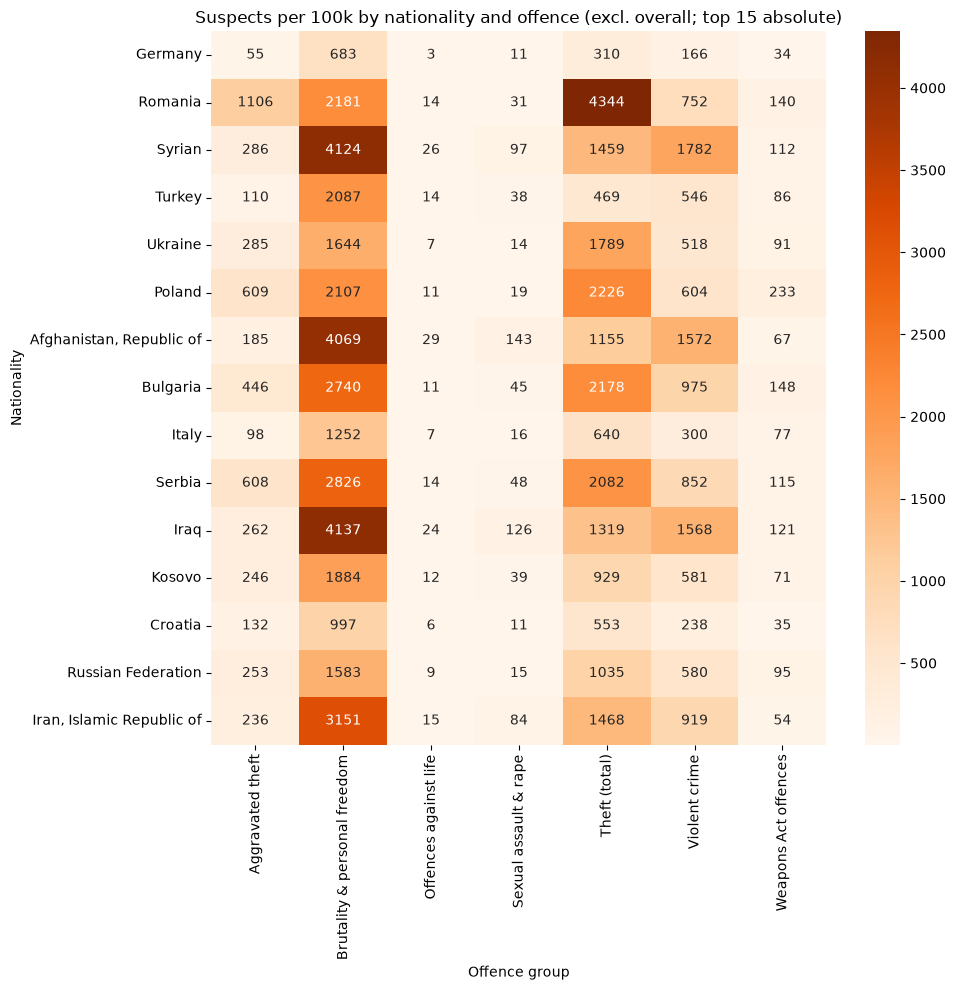

In [16]:
heat_piv = detail.pivot_table(
    index='nationality',
    columns='offence_short',
    values='suspects_per_100k',
    aggfunc='mean',
).reindex(top_abs['nationality'])

plt.figure(figsize=(10, 10))
sns.heatmap(heat_piv, cmap='Oranges', annot=True, fmt='.0f')
plt.title(
    f'Suspects per 100k by nationality and offence '
    f'(excl. overall; top {len(top_abs)} absolute)'
)
plt.xlabel('Offence group')
plt.ylabel('Nationality')
plt.tight_layout()
plt.show()

## High-volume rates for the top 5 absolute leaders

For the top 5 by absolute suspects, Syrian rates sit at the top for both brutality & personal freedom and violent crime (two related groups). Romania stands out on both theft totals and aggravated theft. Germany stays lowest of these five on most of these high-volume groups.

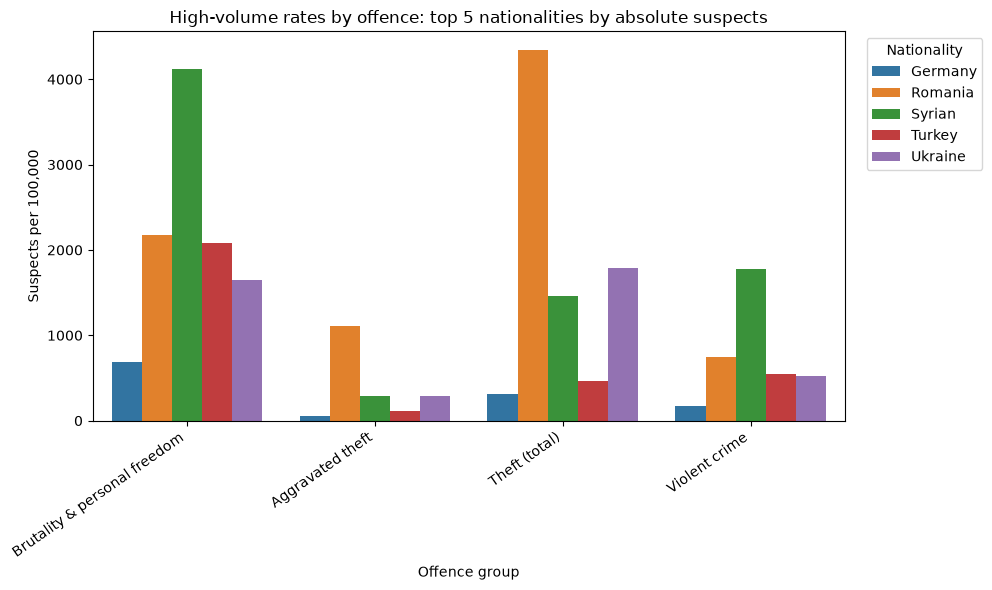

In [17]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=cluster_high,
    x='offence_label',
    y='suspects_per_100k',
    hue='nationality',
    hue_order=list(top_cluster),
    errorbar=None,
)
plt.xticks(rotation=35, ha='right')
plt.xlabel('Offence group')
plt.ylabel('Suspects per 100,000')
plt.title(
    f'High-volume rates by offence: top {CLUSTER_TOP_N} '
    f'nationalities by absolute suspects'
)
plt.legend(title='Nationality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Lower-volume rates: life, sexual assault & rape, Weapons Act

Those three lower groups are hard to read next to high-rate theft and brutality, so this plot shows only them. Syria is again highest on sexual assault & rape and offences against life: about 8.4 times Germany's rate for sexual assault & rape, and about 7.9 times for offences against life.

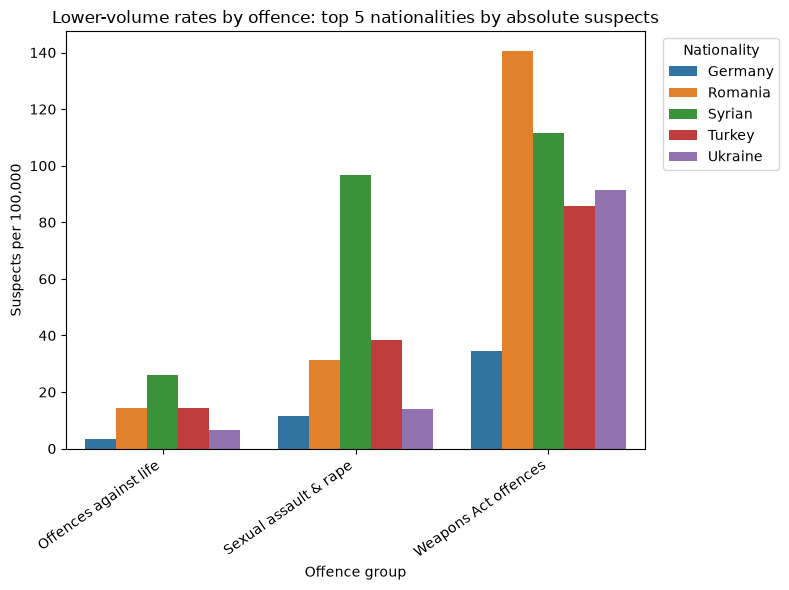

In [18]:
plt.figure(figsize=(8, 6))
sns.barplot(
    data=cluster_rare,
    x='offence_label',
    y='suspects_per_100k',
    hue='nationality',
    hue_order=list(top_cluster),
    errorbar=None,
)
plt.xticks(rotation=35, ha='right')
plt.xlabel('Offence group')
plt.ylabel('Suspects per 100,000')
plt.title(
    f'Lower-volume rates by offence: top {CLUSTER_TOP_N} '
    f'nationalities by absolute suspects'
)
plt.legend(title='Nationality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()